In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [4]:
# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

In [5]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
# Classification before PCA
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
pred1 = model.predict(X_test)
acc1 = accuracy_score(y_test, pred1)

In [8]:
# Apply PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [9]:
# Classification after PCA
model_pca = LogisticRegression(max_iter=5000)
model_pca.fit(X_train_pca, y_train)
pred2 = model_pca.predict(X_test_pca)
acc2 = accuracy_score(y_test, pred2)

In [10]:
# Compare features and accuracy
print("Features before PCA:", X.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")
print("Accuracy before PCA:", round(acc1 * 100, 2), "%")
print("Accuracy after PCA:", round(acc2 * 100, 2), "%")

Features before PCA: 30
Features after PCA: 2
Variance retained: 63.36 %
Accuracy before PCA: 98.25 %
Accuracy after PCA: 94.74 %


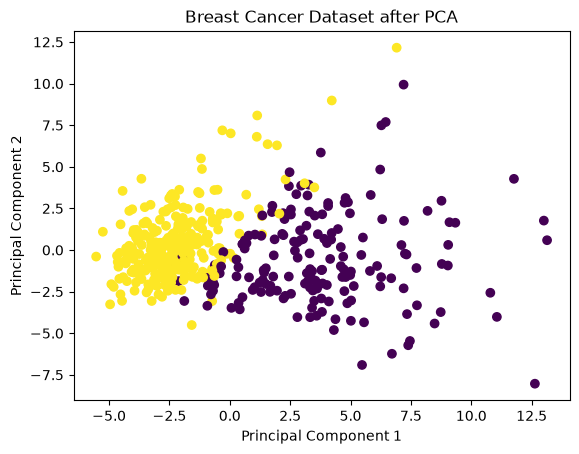

In [11]:
# Visualize reduced dimensions
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Breast Cancer Dataset after PCA")
plt.show()

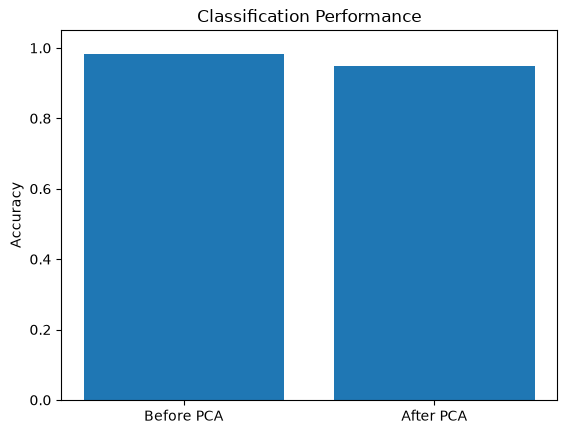

In [12]:
# Compare accuracy
plt.bar(["Before PCA", "After PCA"], [acc1, acc2])
plt.ylabel("Accuracy")
plt.title("Classification Performance")
plt.ylim(0, 1.05)
plt.show()